# AA 279B HW 4

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

## MATLAB

In [2]:
import matlab.engine
from matlab.engine import MatlabEngine

In [3]:
# 1. Start the MATLAB process in the background
print("Starting MATLAB engine...")
eng: MatlabEngine = matlab.engine.start_matlab()

Starting MATLAB engine...


In [4]:
stop = False
if stop:
    eng.quit()

## Setup

In [5]:
import os
import sys

sys.path.insert(0, os.path.abspath('..'))

In [6]:
import numpy as np
from numpy.linalg import norm
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve
from scipy.interpolate import CubicSpline
import matplotlib.pyplot as plt
from lamberthub import vallado2013
import plotly.graph_objects as go
from tqdm import tqdm

from constants import DEG_TO_RAD, AU_TO_KM, MU_SUN, DAY_TO_SEC, R_SUN, HOUR_TO_SEC
from orbital import rv_from_coe
from plotting import plot_3d
from spacetime import greg_to_jd

## Problem 1

### Part a

In [7]:
from orbital import rv_HCI, OrbitalFlyby

rv_HCI(1, 2461333.837872444, eng)

(array([ 50251258.53586901, -31051899.17854478,  -7146562.8599276 ]),
 array([16.04225752, 43.67252438,  2.0977745 ]))

### Part b

In [17]:
gaspra_r_HCI = np.array([7.635070746360724e7, -3.201967071615438e8, 1.17515936590249e7])  # km
gaspra_v_HCI = np.sqrt(MU_SUN/norm(gaspra_r_HCI)) * np.cross([0,0,1], gaspra_r_HCI) / norm(gaspra_r_HCI) # km/s

flybys = [
    OrbitalFlyby("Earth Departure", (1989, 10, 26, 0, 55, 0), 3),
    OrbitalFlyby("Venus Swingby", (1990, 2, 10, 5, 59, 0), 2),
    OrbitalFlyby("Earth Swingby #1", (1990, 12, 8, 20, 35, 0), 3),
    OrbitalFlyby("Gaspra Encounter", (1991, 10, 29, 22, 49, 0), None),
    OrbitalFlyby("Earth Swingby #2", (1992, 12, 8, 15, 9, 0), 3),
    OrbitalFlyby("Jupiter Arrival", (1995, 12, 7, 21, 53, 44), 5)
]
N_FLYBYS = len(flybys)

for flyby in flybys:
    if flyby.planet_num is None:
        flyby.add_rv_HCI(gaspra_r_HCI, gaspra_v_HCI)
    else:
        flyby.add_rv_HCI(*rv_HCI(flyby.planet_num, flyby.jd, eng))

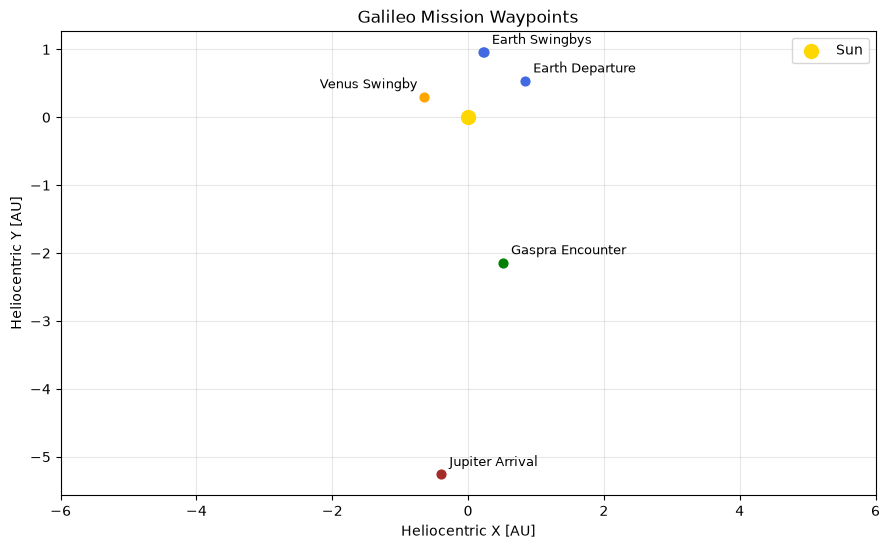

In [14]:
from plotting import plot_flybys

plot_flybys(flybys, xlim=(-6,6))
plt.show()

## Problem 2

### Part a

In [26]:
# Inplace
def calc_transfer(flyby1: OrbitalFlyby, flyby2: OrbitalFlyby):
    """heliocentric asymptotic arrival and departure velocity vectors, using Lambert
    
    `AA279lambert_curtis.m` signature:
    function [v1_out, v2_out, error_out] = AA279lambert_curtis(mu, r1_in, r2_in, dm, nrev, dtsec)
    """
    r1_HCI, r2_HCI = flyby1.r_HCI, flyby2.r_HCI
    t_transfer = (flyby2.jd - flyby1.jd) * DAY_TO_SEC
    result = eng.AA279lambert_curtis(MU_SUN, r1_HCI, r2_HCI, "pro", "ignored", t_transfer, nargout=2)
    
    # heliocentric asymptotic arrival and departure velocity vectors
    v1_HCI, v2_HCI = np.array(result[0]).reshape((3,)), np.array(result[1]).reshape((3,))
    flyby1.v_departure_HCI = v1_HCI
    flyby2.v_arrival_HCI = v2_HCI
    
    # planetocentric asymptotic arrival and departure velocity vectors
    flyby1.v_departure_PCI = v1_HCI - flyby1.v_HCI
    flyby2.v_arrival_PCI = v2_HCI - flyby2.v_HCI
    
for i in range(N_FLYBYS-1):
    calc_transfer(flybys[i], flybys[i+1])

In [60]:
def calc_h(r,v):
    return norm(np.cross(r, v))

relevant_flybys = [flybys[i] for i in [1,2,4]]

for flyby in relevant_flybys:
    vin = norm(flyby.v_arrival_PCI)
    e_before = calc_h(flyby.r_HCI, flyby.v_arrival_HCI)
    vout = norm(flyby.v_departure_PCI)
    e_after = calc_h(flyby.r_HCI, flyby.v_departure_HCI)
    

    print(f"{flyby.name}(HCI):\n\t{vin:.3f} -> {vout:.3f} km/s\t(diff = {2*abs(vout - vin)/(vin+vout) * 100:.3f}%)")
    print(f"\t{e_before:.3e} -> {e_after:.3e} km2/s")

Venus Swingby(HCI):
	6.263 -> 6.041 km/s	(diff = 3.616%)
	3.973e+09 -> 4.237e+09 km2/s
Earth Swingby #1(HCI):
	8.862 -> 8.926 km/s	(diff = 0.722%)
	4.237e+09 -> 5.068e+09 km2/s
Earth Swingby #2(HCI):
	8.915 -> 8.896 km/s	(diff = 0.206%)
	5.069e+09 -> 5.738e+09 km2/s


### Part b

In [61]:
for flyby in relevant_flybys:
    vin = norm(flyby.v_arrival_PCI)
    vout = norm(flyby.v_departure_PCI)
    
    print(f"{flyby.name}(PCI):\n\t{vin:.3f} -> {vout:.3f} km/s")

Venus Swingby(PCI):
	6.263 -> 6.041 km/s
Earth Swingby #1(PCI):
	8.862 -> 8.926 km/s
Earth Swingby #2(PCI):
	8.915 -> 8.896 km/s


### Part c

In [ ]:
for flyby in relevant_flybys:
    vin = norm(flyby.v_arrival_PCI)
    vout = norm(flyby.v_departure_PCI)
    
    print(f"{flyby.name}(PCI):\n\t{vin:.3f} -> {vout:.3f} km/s")

### Part d

In [72]:
def transfer_traj(flyby1: OrbitalFlyby, flyby2: OrbitalFlyby):
    t_arr = np.arange(flyby1.jd * DAY_TO_SEC, flyby2.jd * DAY_TO_SEC, 10000)
    sol = solve_ivp(sun_two_body, (t_arr[0], t_arr[-1]), np.concatenate((flyby1.r_HCI, flyby1.v_departure_HCI)), method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9).y
    return t_arr, sol

t_arrs = []
planet_states = []
for i in range(N_FLYBYS-1):
    t_arr, sol = transfer_traj(flybys[i], flybys[i+1])
    t_arrs.append(t_arr)
    planet_states.append(sol[:3,:].T)

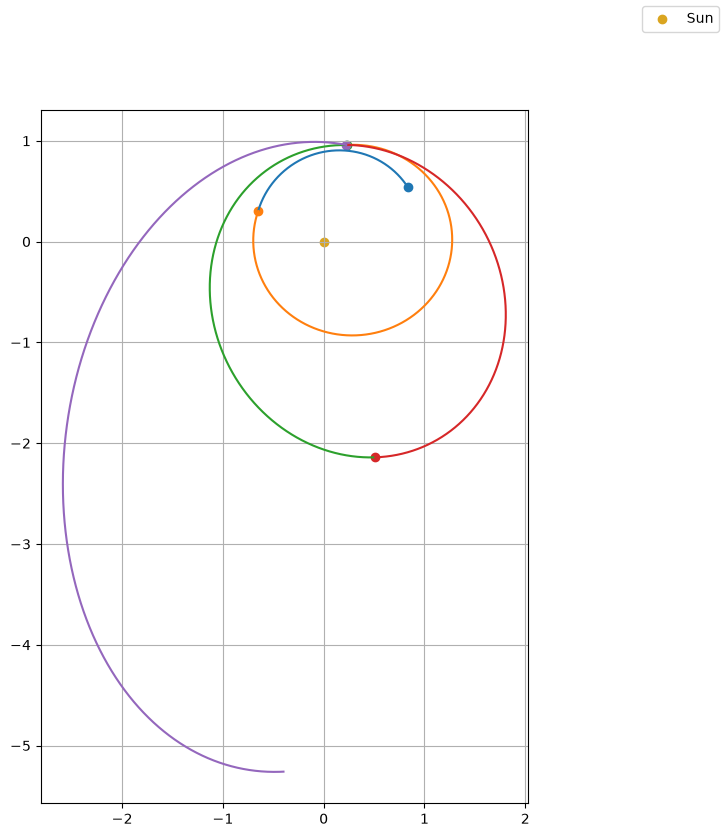

In [86]:
# for flyby,c in zip(relevant_flybys, colors):
#     plot_hyperbolic_characteristics(flyby,c)
    
fig, ax = plt.subplots(figsize=(9, 9))
    
for t,s in zip(t_arrs, planet_states):
    
    ax.plot(s[:,0] / AU_TO_KM, s[:,1] / AU_TO_KM)
    ax.scatter(s[0,0] / AU_TO_KM, s[0,1] / AU_TO_KM)
    
ax.scatter([0],[0], color="goldenrod", label="Sun")
ax.set_aspect("equal")
fig.legend()
ax.grid(True, "both")
plt.show()

In [73]:
plot_3d(planet_states, t_arrs, bodies={"name": "Sun", "radius": R_SUN}, title="Test of Mercury-Earth")

# Extra (junk)

In [50]:
test = False
if test:
    # Just visualizing
    from dynamics import two_body


    def sun_two_body(t,x):
        del t
        return two_body(x, MU_SUN)

    
    jd = 2461333.837872444
    labels = [
        "Mercury",
        "Venus",
        "Earth",
        "Mars",
    ]

    planet_rv = []
    for planet_num in range(4):
        test_r, test_v = rv_HCI(planet_num+1,jd, eng) # 2026-10-20 08:06:32.179
        test_t = np.arange(0, 10*DAY_TO_SEC, HOUR_TO_SEC)
        planet_rv.append(
            solve_ivp(sun_two_body, (test_t[0], test_t[-1]), np.concatenate((test_r, test_v)), method='LSODA', t_eval=test_t, rtol=1e-6, atol=1e-9).y
        )
        
    planet_r = [r.T[:,:3] for r in planet_rv]
    plot_3d(planet_r, test_t, bodies={"name": "Sun", "radius": R_SUN}, labels=labels, title="Test of Mercury-Earth")